In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,precision_score,recall_score,f1_score)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.optimizers import Adam, SGD, RMSprop, AdamW


In [ ]:

df = pd.read_csv("/seeds_dataset.txt", sep=r"\s+", header=None)


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:

feature_names = [
    'area', 'perimeter', 'compactness', 'kernel_length',
    'kernel_width', 'asymmetry_coefficient', 'groove_length', 'Class'
]

df = pd.read_csv("/seeds_dataset.txt", sep=r"\s+", header=None, names=feature_names)

X = df.drop('Class', axis=1)
y_original = df['Class']

print(X.shape)
print(y_original.shape)

(210, 7)
(210,)


In [ ]:
X = df.drop('Class', axis=1)
y_original = df['Class']

print(X.shape)
print(y_original.shape)


(210, 7)
(210,)


In [ ]:
y_mapped = y_original - 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y_mapped, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax"),
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [ ]:
loss="sparse_categorical_crossentropy"

In [ ]:
early_stop = EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True)

In [ ]:
history = model.fit(X_train_scaled,
                    y_train,
                    epochs=100,
                    batch_size=16,
                    validation_split=0.20,
                    callbacks=[early_stop],
                    verbose=1)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.4403 - loss: 1.1694 - val_accuracy: 0.4706 - val_loss: 1.1519
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.4701 - loss: 1.1067 - val_accuracy: 0.5294 - val_loss: 1.0728
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.5000 - loss: 1.0467 - val_accuracy: 0.5588 - val_loss: 1.0059
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5149 - loss: 0.9972 - val_accuracy: 0.5588 - val_loss: 0.9536
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5373 - loss: 0.9569 - val_accuracy: 0.5588 - val_loss: 0.9122
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5672 - loss: 0.9217 - val_accuracy: 0.5882 - val_loss: 0.8795
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5896 - loss: 0.8919 - val_accuracy: 0.5882 - val_loss: 0.8477
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6045 - loss: 0.8616 - val_accuracy: 0.5882 - val_loss:

In [ ]:
# Evaluate the model on the test dataset
y_pred_prob = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, target_names=['Kama', 'Rosa', 'Canadian'])

print(f"Test Accuracy: {accuracy:.4f}\n")
print("Confusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)

In [ ]:
# Evaluate the model on the test dataset
y_pred_prob = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, target_names=['Kama', 'Rosa', 'Canadian'])

print(f"Test Accuracy: {accuracy:.4f}\n")
print("Confusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)

In [ ]:
print("Training completed")


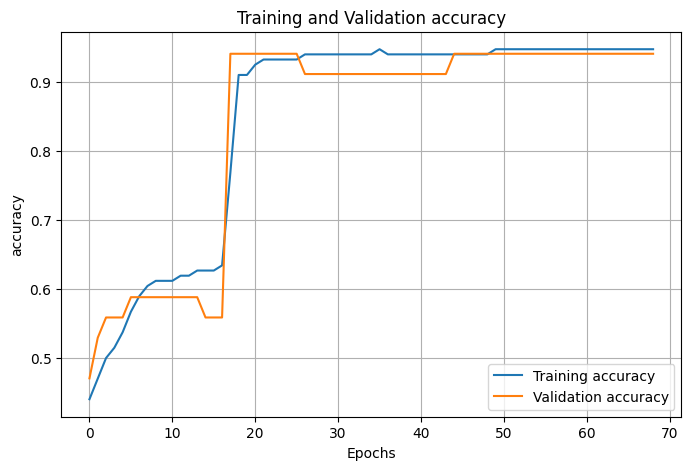

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Training and Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()
plt.grid(True)
plt.show()

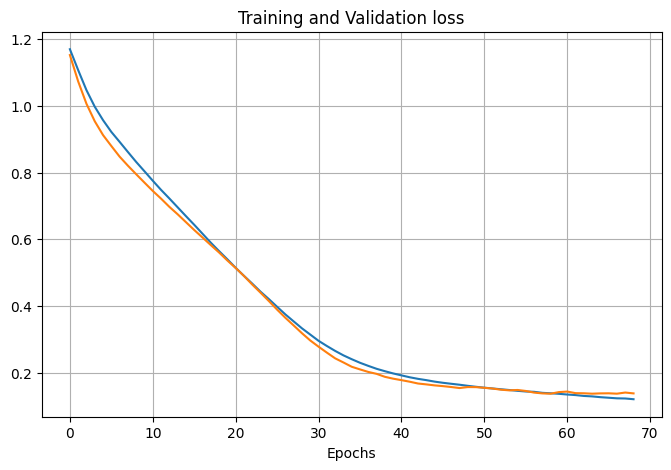

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Training and Validation loss')
plt.xlabel('Epochs')
plt.ylabel
plt.grid(True)
plt.show()

In [ ]:
test_loss,test_accuracy = model.evaluate(X_test_scaled, y_test,verbose=1)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9286 - loss: 0.1824
Test Loss: 0.18236605823040009
Test Accuracy: 0.9285714030265808


In [ ]:
y_prob=model.predict(X_test_scaled,verbose=1)
print(y_prob[:5])
y_pred=np.argmax(y_prob,axis=1)
print(y_pred[:10])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
[[9.9193913e-01 8.9038996e-04 7.1704304e-03]
 [3.3084571e-03 1.9124658e-04 9.9650025e-01]
 [1.0479235e-02 9.8855376e-01 9.6705608e-04]
 [8.4648597e-01 3.7058606e-03 1.4980817e-01]
 [5.2366549e-01 5.4754538e-04 4.7578695e-01]]
[0 2 1 0 0 2 0 2 0 2]


In [ ]:
y_pred=np.argmax(y_prob,axis=1)
print("predicted encoded classes:")
print(y_pred[:10])

predicted encoded classes:
[0 2 1 0 0 2 0 2 0 2]


In [ ]:
y_pred_original=y_pred+1
y_test_original=y_test+1
print("predicted classes:")
print(y_pred_original[:10])


predicted classes:
[1 3 2 1 1 3 1 3 1 3]


In [ ]:
comparison_df=pd.DataFrame({"Actual":y_test_original,"Predicted":y_pred_original})
print(comparison_df.head(10))
#

     Actual  Predicted
30        1          1
172       3          3
84        2          2
199       3          1
60        1          1
155       3          3
45        1          1
182       3          3
9         1          1
196       3          3


In [ ]:
accuracy=accuracy_score(y_test_original,y_pred_original)
print(f"Accuracy: {accuracy}")

Accuracy: 0.9285714285714286


In [ ]:
precision=precision_score(y_test_original,y_pred_original,average="weighted")
print(f"Precision: {precision}")
#

Precision: 0.9310515873015874


In [ ]:
recall = recall_score(y_test_original, y_pred_original, average="weighted")
print(f"Recall: {recall}")

Recall: 0.9285714285714286


In [ ]:
f1=f1_score(y_test_original,y_pred_original,average="weighted")
print(f"F1 Score: {f1}")
#

F1 Score: 0.9290419725202332


In [ ]:
metrics=pd.dataframse("Accuracy","Precision","Recall","F1 Score")
print(metrics)

AttributeError: module 'pandas' has no attribute 'dataframse'

In [ ]:
cm=confusion_matrix(y_test_original,y_pred_original)
print(cm)

[[10  0  1]
 [ 0 14  0]
 [ 2  0 15]]


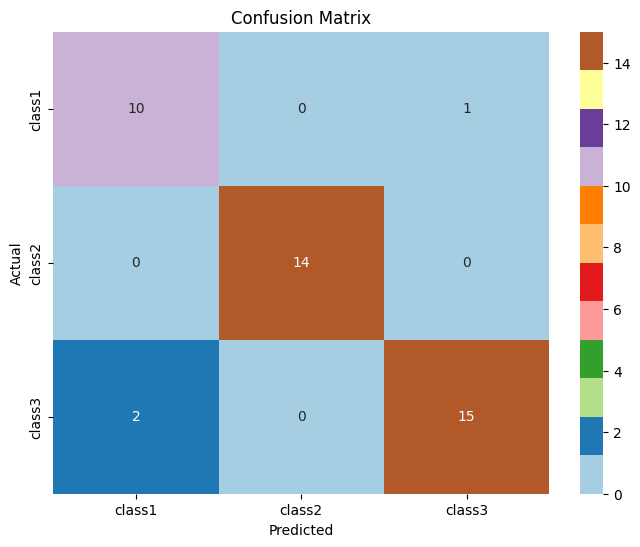

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Paired",xticklabels=["class1","class2","class3"], yticklabels=["class1","class2","class3"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
#